## 02 - Visualizing the k=10..20 Large-k Sweep (XDec-CHI Table S3 Gene List, n=182)

### Aim
* Visualize Figure 2 - the gene-level correlation between the Peng et al. reference and each k's estimated
  profiles - for the XDec "with refs" Stage 1/2 reruns at `k=10..20` on the same full 182-sample TCGA-PAAD
  cohort and Peng et al. reference as `large_k_EDA/02_visualization_large_k.ipynb`, but using XDec-CHI's own
  283-gene Table S3 probe list (282 symbols recovered) instead of this project's 344-gene Stage-0 list.
  
### Input
* `data/deconvolution/xdec/gene_lists/xdec_chi_table_s3_genes.txt` - XDec-CHI's 283-gene Table S3 list
  (282 symbols recovered).
* `data/deconvolution/xdec/{refs.tsv, ref_metadata.tsv}` - Peng et al. 2019 single-cell reference (notebook 04).
* `data/deconvolution/xdec/stage1_with_refs_k{10..20}_paperGenes/{cell_type_profiles.tsv,proportions.tsv}` -
  the 11 large-k sweep reruns produced by `large_k_EDA_paperGenes/run_large_k_sweep_paperGenes.sh` (same
  182-sample cohort and Peng reference as `large_k_EDA/run_large_k_sweep.sh`, Table S3 gene list instead of
  the 344-gene Stage-0 list).

### Output
* `large_k_EDA_paperGenes/figures/fig_profile_reference_correlation_clustermap_k{10..20}.png` - one heatmap
  per k of Spearman correlation between that k's estimated profiles (fixed `Profile_1..k` order) and
  reference pseudo-bulks, pseudo-bulks sorted into the fixed biological-compartment cell-type blocks.

### Steps
1. Restrict the Table S3 gene list to genes present in both `refs.tsv` and every k's `cell_type_profiles.tsv`.
2. Build one (patient, cell type) pseudo-bulk reference per group from that gene set (independent of k).
3. Figure 2: for each k in 10..20, Spearman-correlate that k's profiles against every pseudo-bulk and plot a
   compartment-sorted clustermap, looping over all 11 sweep results.
4. Best-matching cell type per profile, across k.
5. Recommend k=14 and interpret each of its 14 profiles (best/runner-up reference match, gap, dominant-
   sample count, breadth of correlation) to flag which are clean cell-type calls vs. ambiguous vs. likely
   NNLS artifacts.

### Result
* Across k=10..20, k=14 has the best reference cell-type coverage (9/10 types reached by at least one
  profile) without the broad, correlates-with-everything artifact profile seen at k=12 in the 344-gene-list
  sweep (`large_k_EDA/02_visualization_large_k.ipynb`).
* At k=14: ~3/14 profiles are clean single-cell-type matches, ~7/14 are plausible-but-ambiguous (small gap to
  the runner-up type), and 2/14 are not resolved at all (near-zero/negative best correlation) - including
  Profile_13, which dominates 117/182 (64%) of samples yet correlates negatively with every reference
  type. See Step 5 below for the full per-profile table and classification.

### Conclusion
* k=14 is the best k in this sweep for resolving distinct reference cell types under the paper's own Table
  S3 gene list, and it avoids one specific failure mode (the broad non-specific artifact) that the project's
  344-gene list hits at k=12. It does not avoid the other recurring failure mode: the single largest
  profile still fails to correlate with any Peng et al. reference cell type, consistent with that profile
  representing malignant/cancer epithelium the normal-tissue single-cell reference cannot capture - the same
  limitation seen across every k and gene list tried in this project so far, not something specific to k=14
  or to this gene list.


In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# This notebook lives in progress/large_k_EDA_paperGenes/; Jupyter starts the kernel with
# cwd = the notebook's own folder, and every "data/..." path below is relative to progress/.
if os.path.basename(os.getcwd()) == "large_k_EDA_paperGenes":
    os.chdir("..")

XDEC_DIR = "data/deconvolution/xdec"
FIG_DIR = os.path.join("large_k_EDA_paperGenes", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

K_VALUES = list(range(10, 21))

mpl.rcParams.update({"font.family": "sans-serif", "font.size": 8, "axes.linewidth": 0.6, "pdf.fonttype": 42})

# Single-hue sequential blue ramp (magnitude encoding), light -> dark - matches this
# project's other publication-style figures (notebook 10, paper_duplication/02_visualization.ipynb,
# large_k_EDA/02_visualization_large_k.ipynb).
SEQ_BLUE_STEPS = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
                  "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
seq_blue = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE_STEPS, N=256)

os.getcwd()


'/Users/liruixi/Desktop/i20_transfer/QCB/rotation/Alex/XDec_Pancreatic_Cancer/progress'

### Step 1: restrict the Table S3 gene list to genes present in the reference and in every k's profiles

In [2]:
probes = [l.strip() for l in open(os.path.join(XDEC_DIR, "gene_lists", "xdec_chi_table_s3_genes.txt")) if l.strip()]

refs = pd.read_csv(os.path.join(XDEC_DIR, "refs.tsv"), sep="\t", index_col=0)
ref_meta = pd.read_csv(os.path.join(XDEC_DIR, "ref_metadata.tsv"), sep="\t", index_col=0)

profiles_by_k = {
    k: pd.read_csv(os.path.join(XDEC_DIR, f"stage1_with_refs_k{k}_paperGenes", "cell_type_profiles.tsv"), sep="\t", index_col=0)
    for k in K_VALUES
}

genes = [g for g in probes if g in refs.index and all(g in profiles_by_k[k].index for k in K_VALUES)]
print(f"{len(genes)}/{len(probes)} of the Table S3 genes present in refs.tsv and every k={K_VALUES[0]}..{K_VALUES[-1]} cell_type_profiles.tsv")

ref_cell_types = ref_meta.loc[refs.columns, "Cell_Type"]

# Fixed biological-compartment order (not alphabetical) so visually/functionally related cell types sit
# next to each other: pancreatic epithelial/parenchymal, then stroma, then immune - matches
# paper_duplication/02_visualization.ipynb, large_k_EDA/02_visualization_large_k.ipynb, and notebook 11.
cell_type_order = [
    "pancreatic acinar cell", "pancreatic ductal cell", "enteroendocrine cell",   # pancreatic epithelium
    "pancreatic stellate cell", "fibroblast", "blood vessel endothelial cell", "neural cell",  # stroma
    "T cell", "lymphocyte of B lineage", "myeloid leukocyte",                     # immune
]
assert set(cell_type_order) == set(ref_cell_types.unique()), "cell_type_order must cover every reference cell type"
cell_palette = dict(zip(cell_type_order, sns.color_palette("tab10", n_colors=len(cell_type_order))))


247/282 of the Table S3 genes present in refs.tsv and every k=10..20 cell_type_profiles.tsv


### Step 2: build (patient, cell type) pseudo-bulks - independent of k

Matching the gene-level approach used elsewhere in this project (notebook 10's Figure 2A duplicate,
`paper_duplication/02_visualization.ipynb`, and `large_k_EDA/02_visualization_large_k.ipynb`): single cells
are averaged into one pseudo-bulk per (patient, cell type) pair over the shared gene list. This only depends
on `refs.tsv`/`ref_metadata.tsv` and the gene list, so it is computed once and reused for every k in Figure 2.

Why pseudo-bulk instead of correlating against raw single cells:
* `cell_type_profiles.tsv` (Figure 2's other axis) is a smooth, bulk-aggregated signal; a single cell is
  sparse and dropout-noisy, so correlating one against the other is dominated by single-cell noise rather
  than biology.
* Averaging within each (patient, cell type) group denoises the reference side enough to be comparable,
  without collapsing away the patient-to-patient variation that gives each cell type a distribution of
  correlation values (used for the mean-match table in Step 4) rather than one number.
* `scripts/10_xdec_paper_figure_duplication.ipynb` tried the raw-single-cell version first and got an
  unreadable result (column-block purity under 0.3 for 7 of 10 cell types) - pseudo-bulking is what made
  this correlation legible at all.

In [3]:
ref_sub = refs.loc[genes]
patients = pd.Series(ref_sub.columns, index=ref_sub.columns).str.split("_").str[0]
group_key = patients.astype(str) + " | " + ref_cell_types.astype(str)
pseudobulk = ref_sub.T.groupby(group_key).mean().T
pb_cell_types = pd.Series({c: c.split(" | ")[1] for c in pseudobulk.columns})
print(f"{ref_sub.shape[1]} single cells -> {pseudobulk.shape[1]} (patient x cell type) pseudo-bulk references")

pb_types = pd.Categorical(pb_cell_types, categories=cell_type_order, ordered=True)
pb_col_order = pd.Series(pb_types, index=pb_cell_types.index).sort_values(kind="stable").index
pseudobulk = pseudobulk[pb_col_order]
pb_cell_types = pb_cell_types.loc[pb_col_order]

pb_col_colors = pb_cell_types.map(cell_palette)
pb_col_colors.name = "Cell type"


2748 single cells -> 270 (patient x cell type) pseudo-bulk references


### Step 3: Figure 2 - profiles vs. reference pseudo-bulks, gene-level granularity, looped over k=10..20

Each k's estimated profiles (`cell_type_profiles.tsv`) are Spearman-correlated against every pseudo-bulk
individually, restricted to the Table S3 gene list from Step 1. Pseudo-bulks (columns) are sorted into the
fixed `cell_type_order` biological-compartment blocks - never reordered by clustering; profiles (rows) are
left in fixed `Profile_1..k` order.

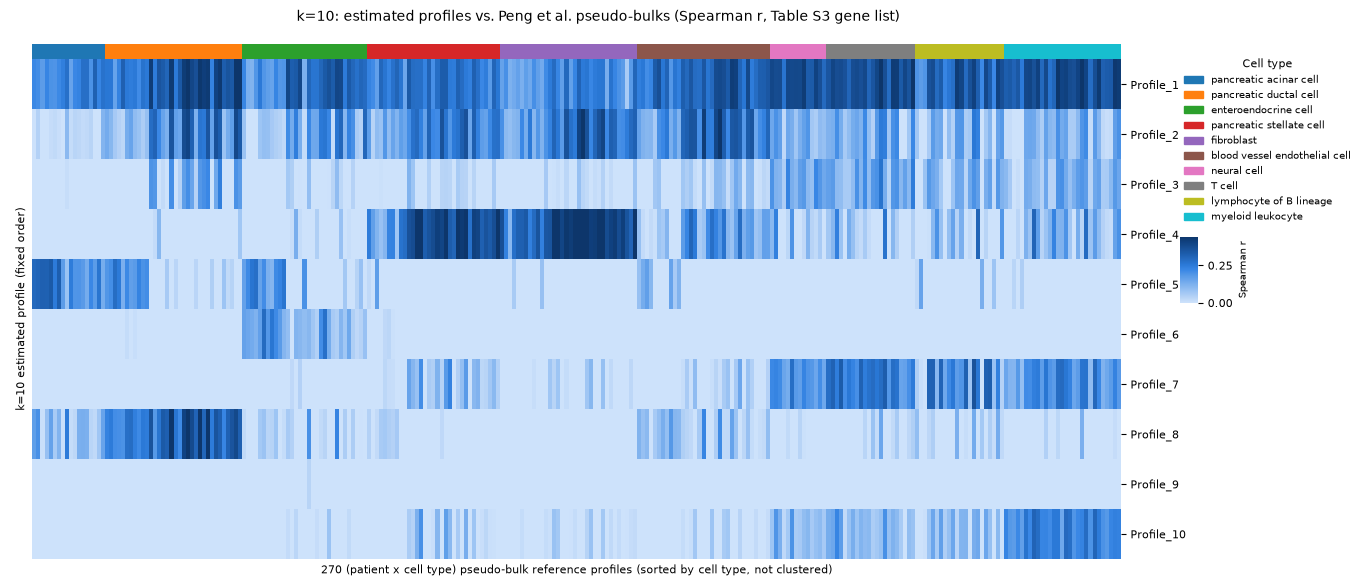

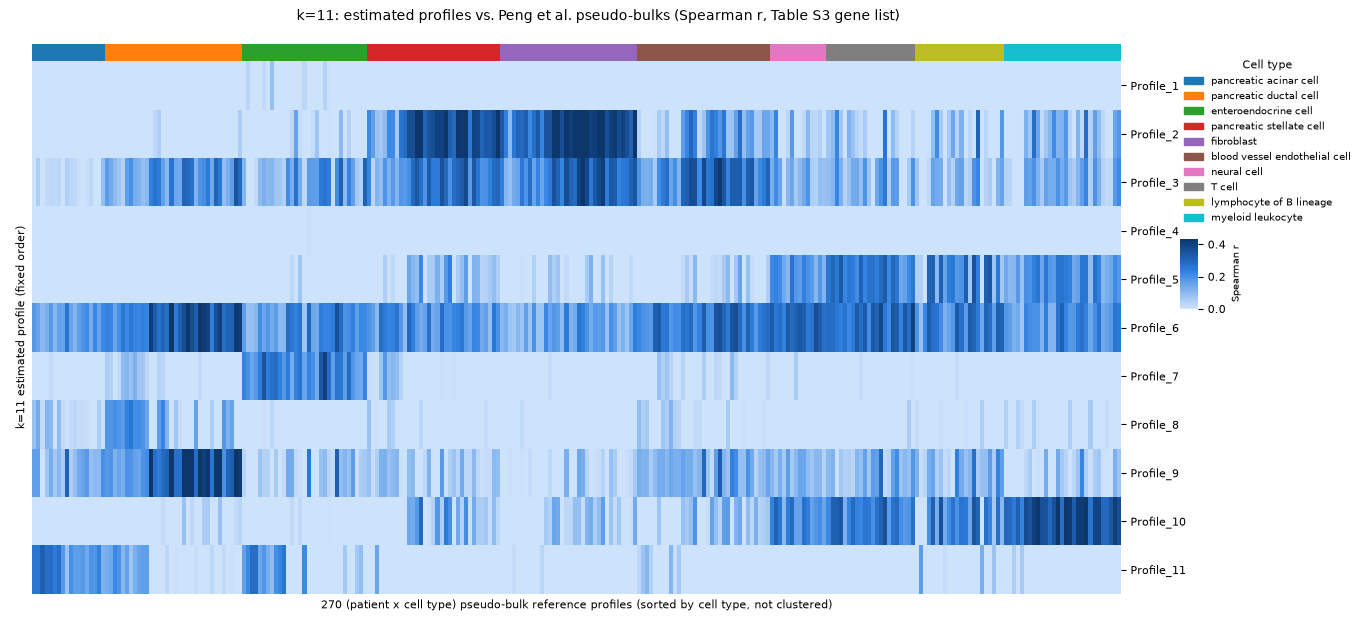

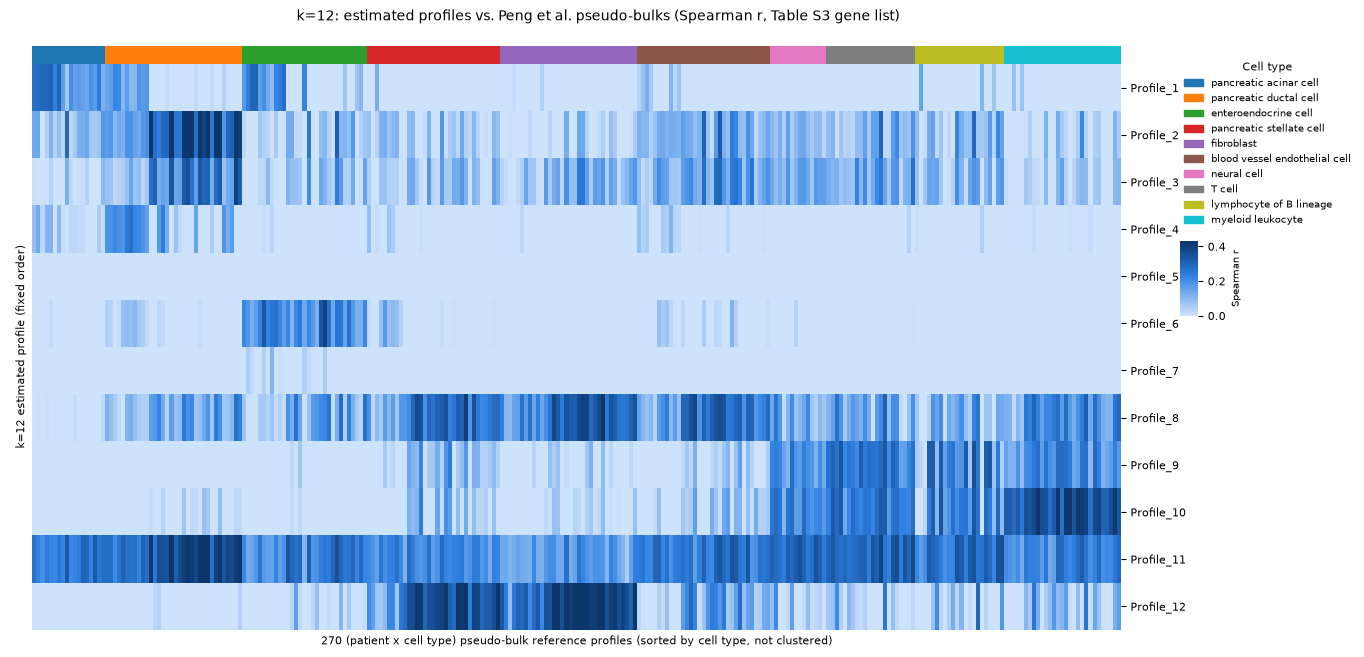

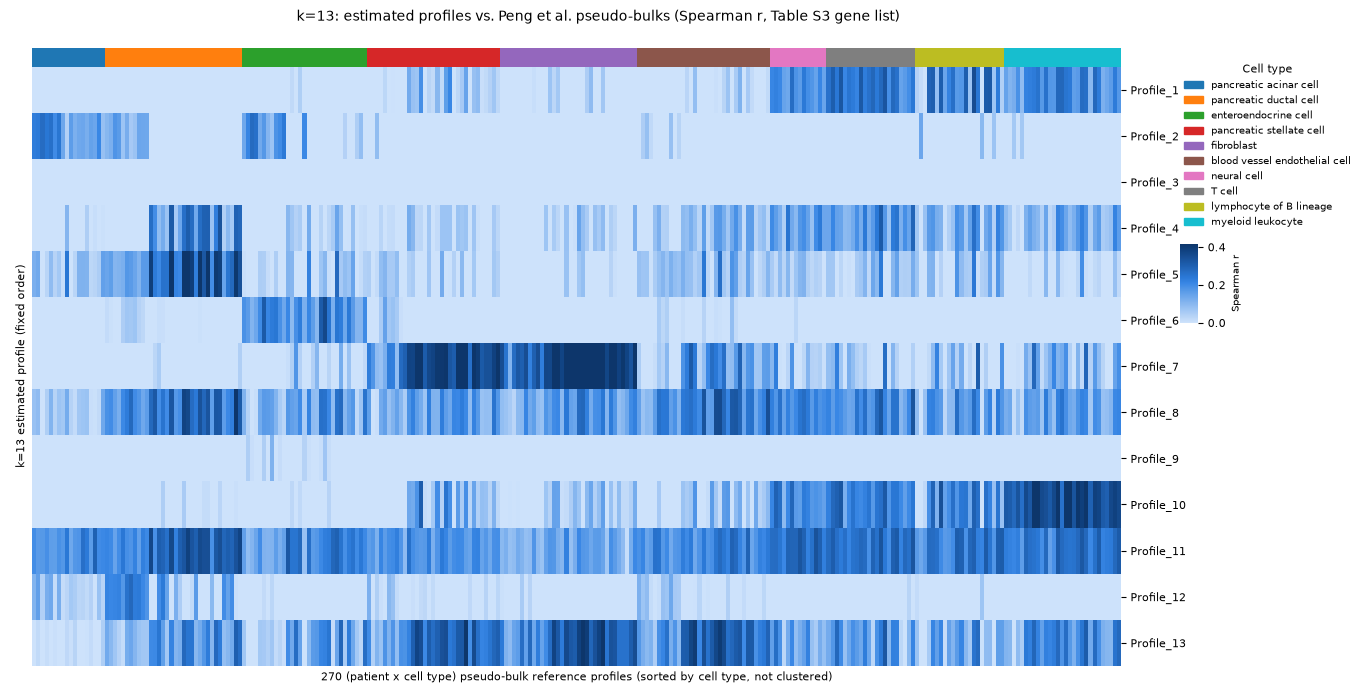

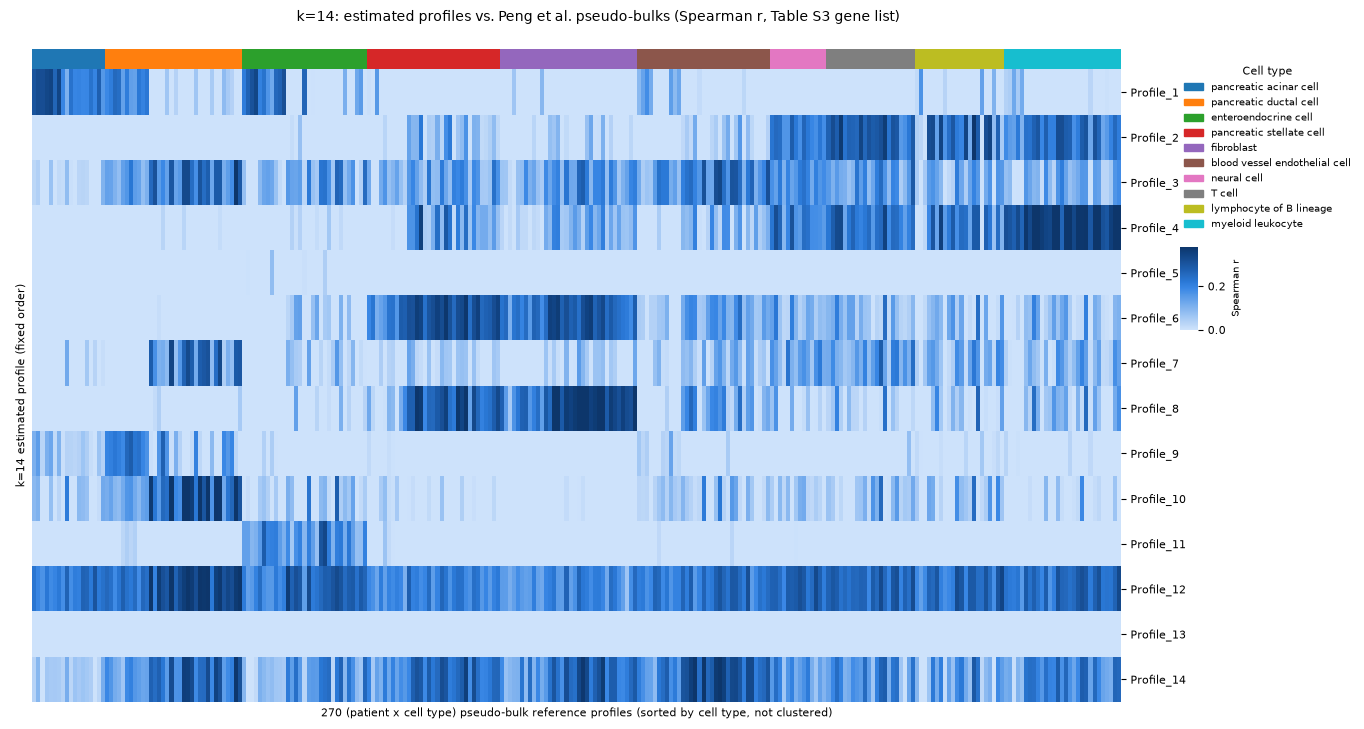

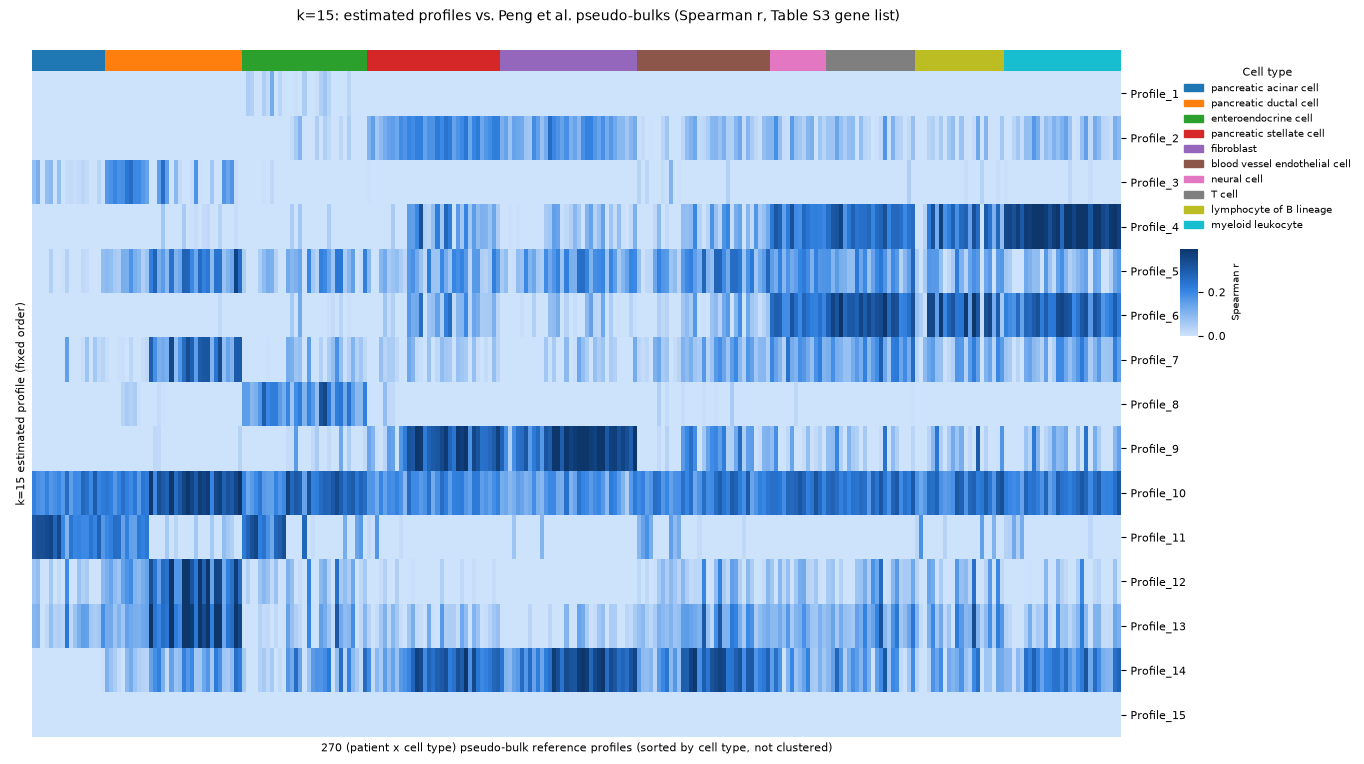

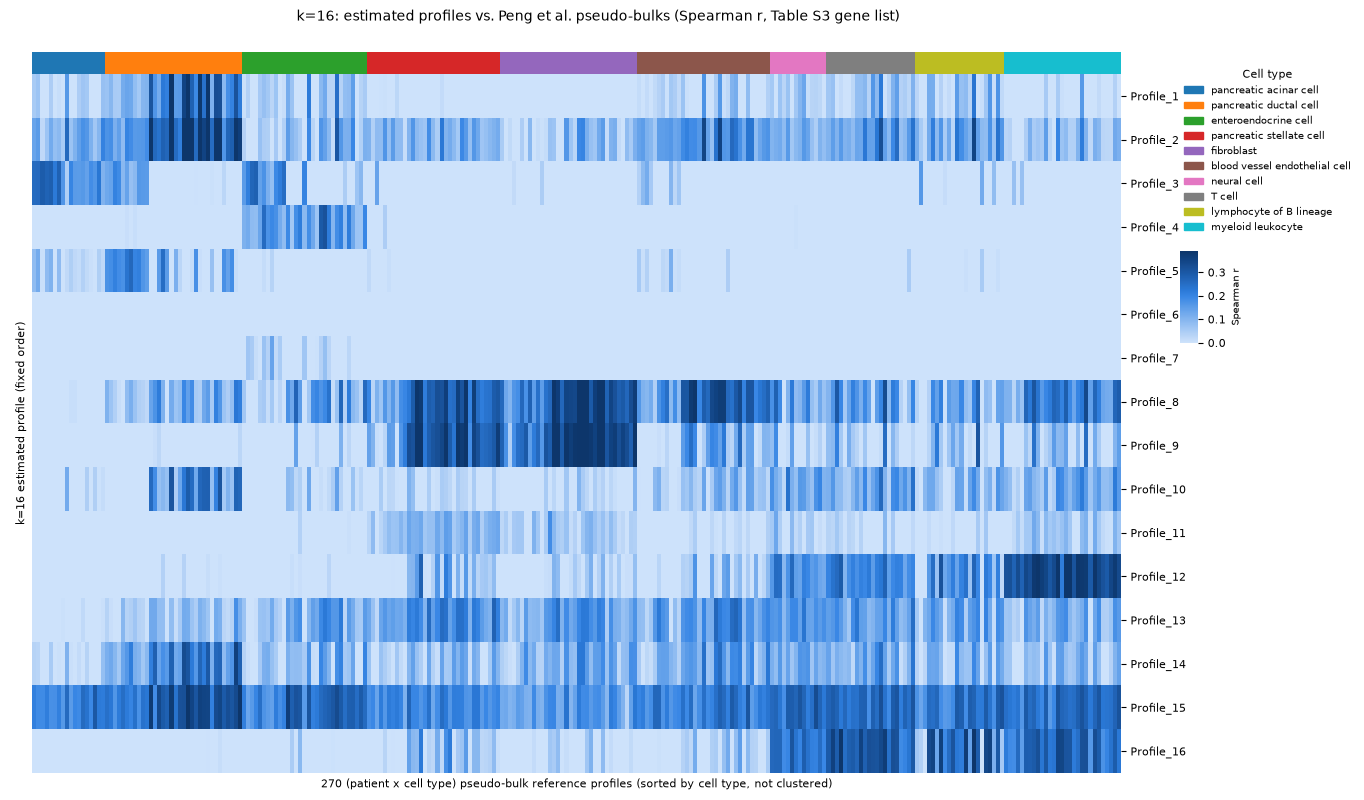

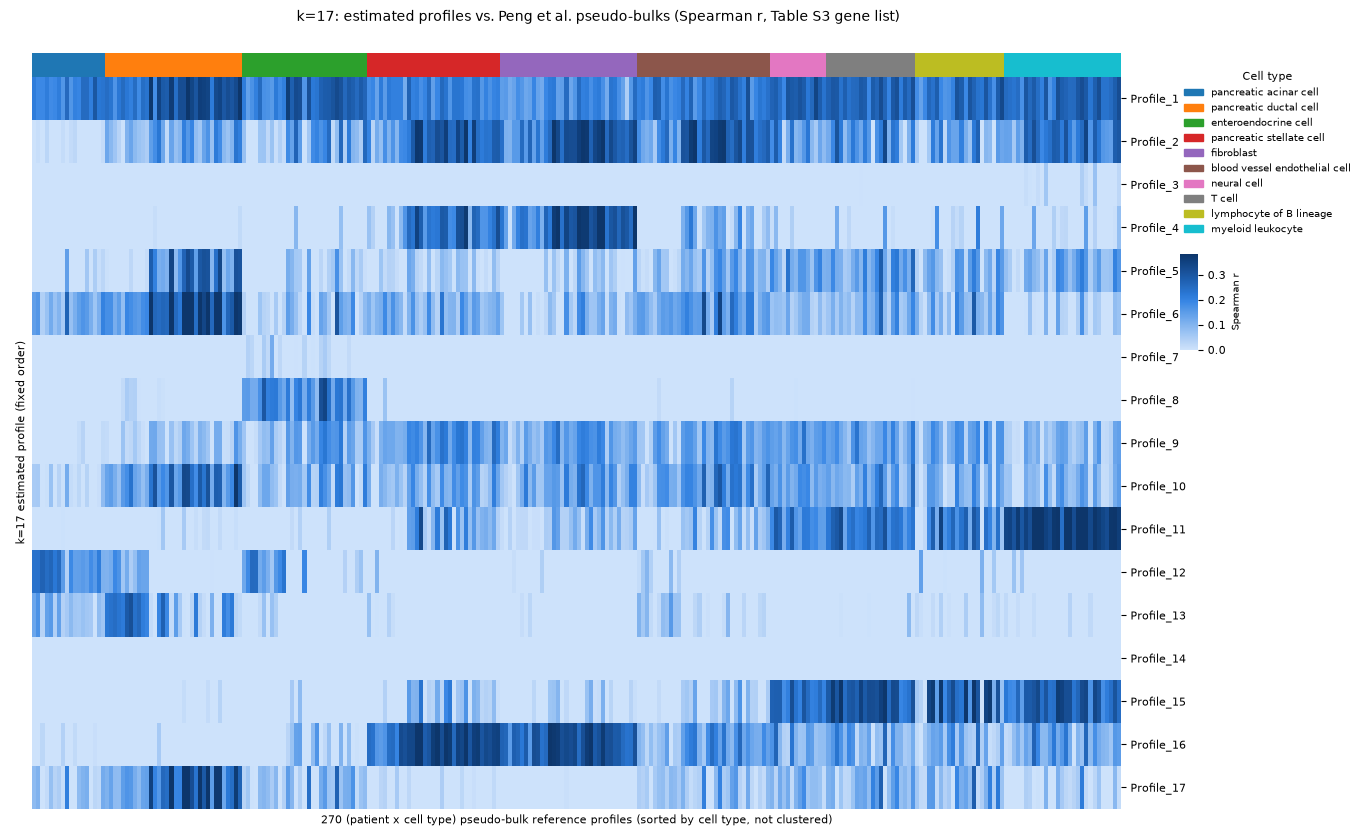

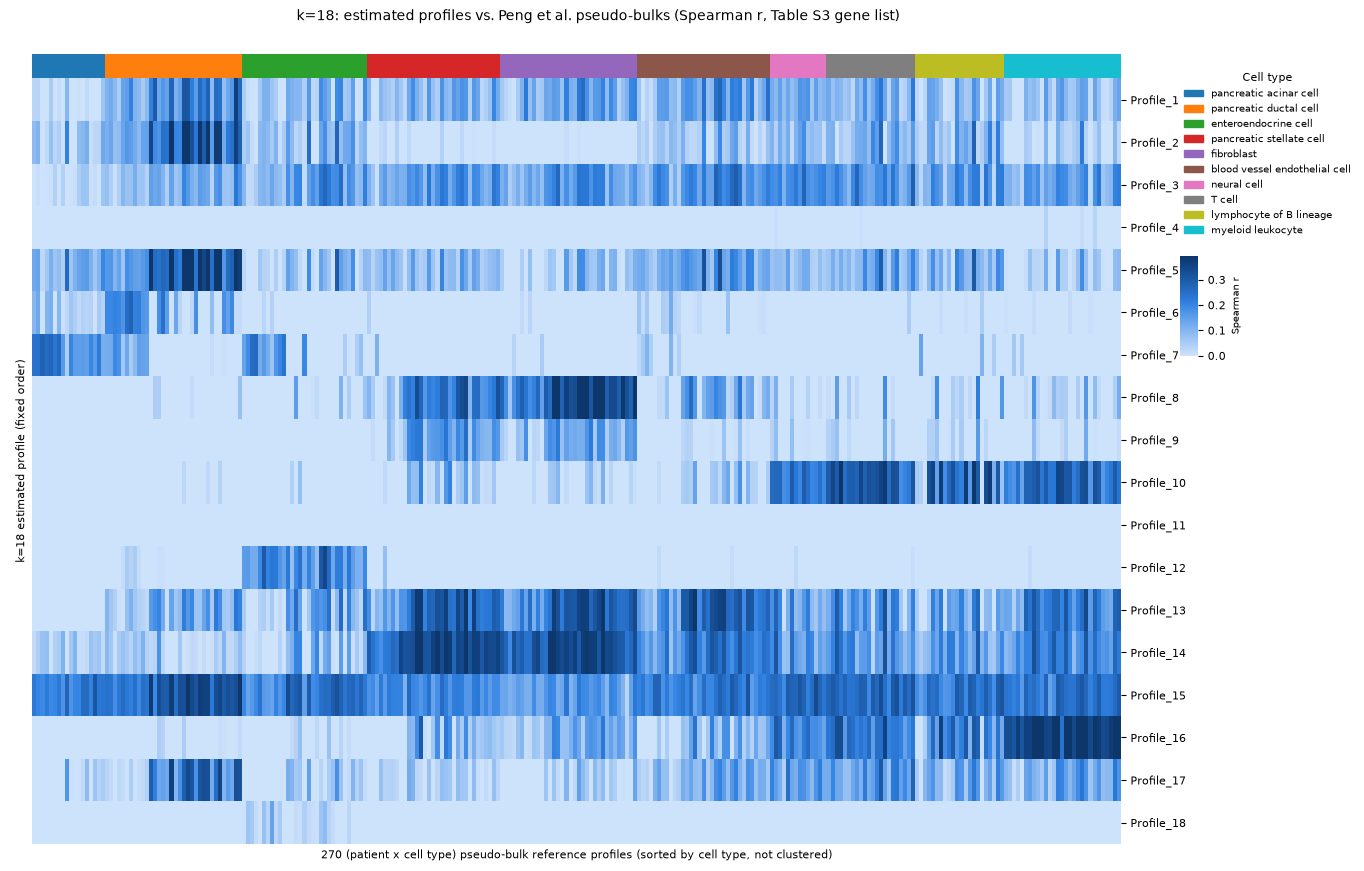

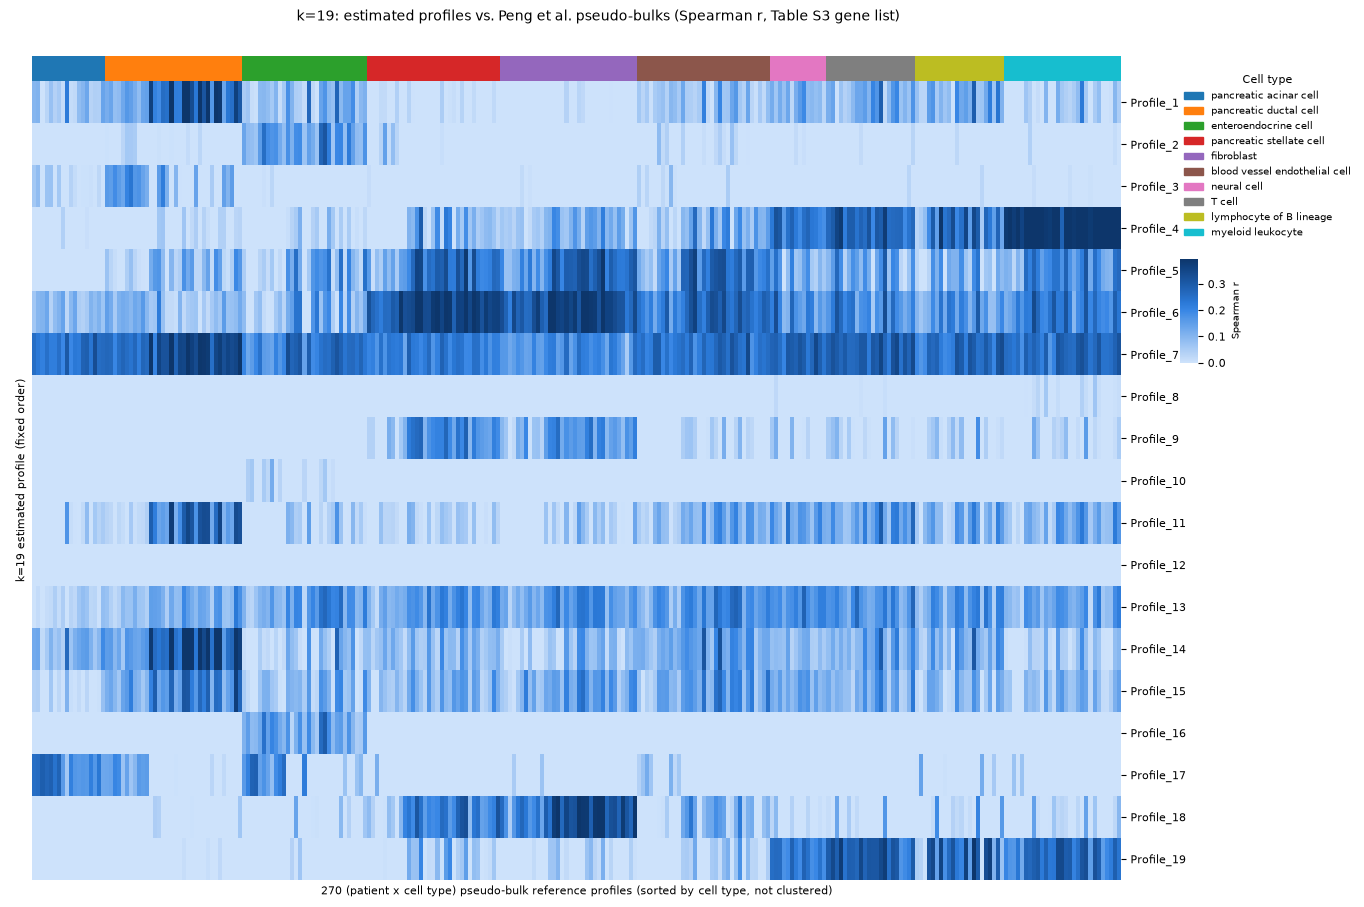

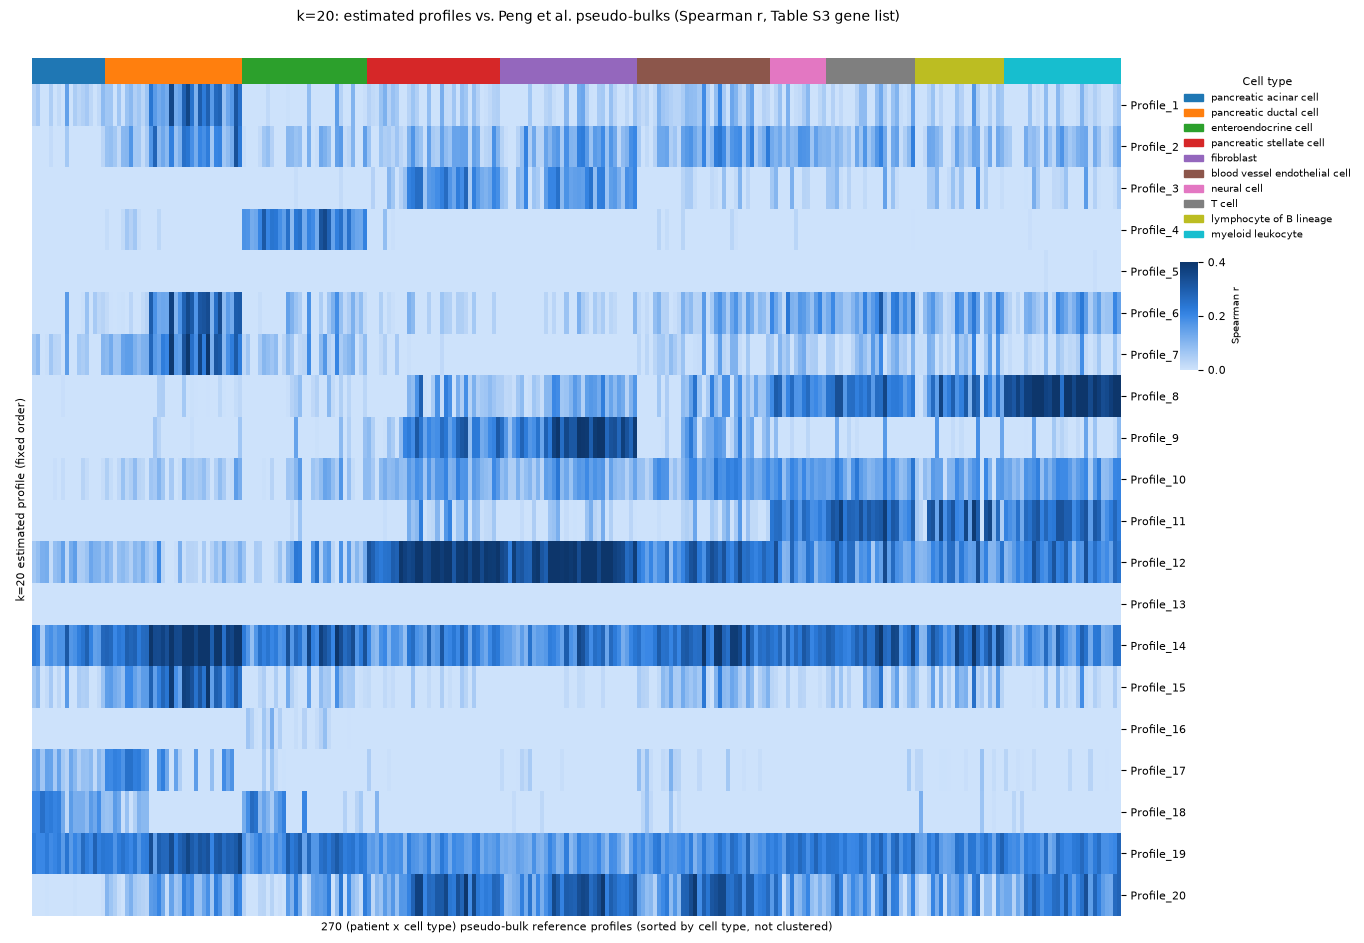

In [4]:
corr_by_k = {}

for k in K_VALUES:
    profile_order = [f"Profile_{i}" for i in range(1, k + 1)]
    combined = pd.concat([pseudobulk, profiles_by_k[k].loc[genes, profile_order]], axis=1)
    corr_full = combined.corr(method="spearman")
    corr_k = corr_full.loc[profile_order, pseudobulk.columns]
    corr_by_k[k] = corr_k

    g2 = sns.clustermap(
        corr_k, row_cluster=False, col_cluster=False,
        col_colors=pb_col_colors.values,
        cmap=seq_blue, vmin=0, vmax=float(np.percentile(corr_k.values, 99)),
        xticklabels=False, yticklabels=True,
        figsize=(12, 0.35 * k + 2), cbar_kws={"label": "Spearman r"},
        dendrogram_ratio=(0.02, 0.02),
    )
    g2.ax_heatmap.set_xlabel(f"{corr_k.shape[1]} (patient x cell type) pseudo-bulk reference profiles (sorted by cell type, not clustered)")
    g2.ax_heatmap.set_ylabel(f"k={k} estimated profile (fixed order)")
    g2.ax_heatmap.yaxis.set_label_position("left")
    g2.ax_heatmap.tick_params(axis="y", rotation=0)
    handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
    legend2 = g2.ax_heatmap.legend(handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
                                    loc="upper left", fontsize=7, title_fontsize=8, frameon=False)
    g2.fig.suptitle(f"k={k}: estimated profiles vs. Peng et al. pseudo-bulks (Spearman r, Table S3 gene list)",
                     y=1.02, fontsize=10)

    g2.cax.yaxis.label.set_fontsize(7)
    g2.fig.canvas.draw()
    legend_bbox = legend2.get_window_extent(g2.fig.canvas.get_renderer()).transformed(g2.fig.transFigure.inverted())
    cbar_width, cbar_height, gap = 0.015, 0.12, 0.02
    g2.cax.set_position([legend_bbox.x0, legend_bbox.y0 - cbar_height - gap, cbar_width, cbar_height])

    g2.savefig(os.path.join(FIG_DIR, f"fig_profile_reference_correlation_clustermap_k{k}.png"), dpi=200, bbox_inches="tight")
    plt.show()


### Step 4: best-matching cell type per profile, across k

For each k, the reference cell type whose pseudo-bulks have the highest mean Spearman r against each
profile - a compact readout of how cleanly each profile maps onto a single reference cell type as k grows
from 10 to 20, without having to re-read all 11 clustermaps above.

In [5]:
best_match_rows = []
for k in K_VALUES:
    corr_k = corr_by_k[k]
    mean_by_type = corr_k.T.groupby(pb_cell_types.loc[corr_k.columns]).mean().T  # profiles x cell types
    for profile in mean_by_type.index:
        best_type = mean_by_type.loc[profile].idxmax()
        best_match_rows.append({
            "k": k, "profile": profile,
            "best_matching_cell_type": best_type,
            "mean_spearman_r": mean_by_type.loc[profile, best_type],
        })

best_match = pd.DataFrame(best_match_rows)
best_match


,k,profile,best_matching_cell_type,mean_spearman_r
0,10,Profile_1,T cell,0.373657
1,10,Profile_2,blood vessel endothelial cell,0.250962
2,10,Profile_3,T cell,0.145670
3,10,Profile_4,fibroblast,0.376695
4,10,Profile_5,pancreatic acinar cell,0.230051
...,...,...,...,...
160,20,Profile_16,enteroendocrine cell,-0.003344
161,20,Profile_17,pancreatic acinar cell,0.090204
162,20,Profile_18,pancreatic acinar cell,0.158240
163,20,Profile_19,pancreatic ductal cell,0.267633


### Step 5: why k=14, and interpreting each of its profiles

**Why k=14 over the other k's in this sweep:**
* It reaches the most reference cell types of any k in 10..20 (9/10, via `best_match` above), without losing
  much correlation quality relative to the lower k's.
* It does **not** show the broad "correlates positively with nearly every cell type, near-zero sample
  prevalence" artifact that recurs in this project's 344-gene-list sweep (e.g. Profile_11 at k=12 in
  `large_k_EDA/02_visualization_large_k.ipynb`, Profile_7 at k=8 in `scripts/10_xdec_paper_figure_duplication.ipynb`) -
  no profile here correlates at r>0.3 with more than one reference type at once.
* It still has the *other* recurring failure mode (one dominant profile uncorrelated with any reference
  type - see Profile_13 below), just as every other k/gene-list combination tried in this project does; this
  looks like a reference limitation (Peng et al.'s normal-tissue single cells cannot represent malignant
  epithelium), not something k=14 or the Table S3 gene list caused or could fix.

**Method:** for k=14, take the best- and runner-up-matching reference cell type per profile from
`mean_by_type` (Step 4's per-type average of `corr_by_k[14]`), the gap between them, how many samples each
profile dominates (top proportion) in `proportions.tsv`, and how many reference types it correlates with at
r>0.3 (a breadth check for the "correlates with everything" artifact pattern).

In [6]:
k14 = 14
k14_profile_order = [f"Profile_{i}" for i in range(1, k14 + 1)]
mean_by_type_k14 = corr_by_k[k14].T.groupby(pb_cell_types.loc[corr_by_k[k14].columns]).mean().T

props_k14 = pd.read_csv(os.path.join(XDEC_DIR, f"stage1_with_refs_k{k14}_paperGenes", "proportions.tsv"), sep="\t", index_col=0)
dominant_counts_k14 = props_k14.idxmax(axis=1).value_counts()

rows = []
for p in k14_profile_order:
    row = mean_by_type_k14.loc[p].sort_values(ascending=False)
    rows.append({
        "profile": p,
        "best_match": row.index[0], "best_r": row.iloc[0],
        "runner_up": row.index[1], "runner_up_r": row.iloc[1],
        "gap": row.iloc[0] - row.iloc[1],
        "n_dominant_samples": int(dominant_counts_k14.get(p, 0)),
        "n_types_r_gt_0.3": int((row > 0.3).sum()),
    })
k14_summary = pd.DataFrame(rows).set_index("profile")
k14_summary.round(3)


,best_match,best_r,runner_up,runner_up_r,gap,n_dominant_samples,n_types_r_gt_0.3
profile,,,,,,,
Profile_1,pancreatic acinar cell,0.245,enteroendocrine cell,0.054,0.192,0,0
Profile_2,T cell,0.278,myeloid leukocyte,0.225,0.052,4,0
Profile_3,pancreatic ductal cell,0.202,blood vessel endothelial cell,0.193,0.009,8,0
Profile_4,myeloid leukocyte,0.361,T cell,0.234,0.126,8,1
Profile_5,enteroendocrine cell,-0.054,pancreatic stellate cell,-0.223,0.169,0,0
Profile_6,pancreatic stellate cell,0.280,fibroblast,0.263,0.017,2,0
Profile_7,T cell,0.142,neural cell,0.133,0.010,5,0
Profile_8,fibroblast,0.309,pancreatic stellate cell,0.216,0.093,6,1
Profile_9,pancreatic ductal cell,0.111,pancreatic acinar cell,0.054,0.056,6,0


**Per-profile interpretation (k=14, Table S3 gene list), from the table above:**

✅ **Clean single-cell-type match** (clear gap over runner-up, plausible biology)
* **Profile_1 -> pancreatic acinar cell** (gap ~0.19)
* **Profile_10 -> pancreatic ductal cell** (gap ~0.20, dominant in 10 samples)
* **Profile_11 -> enteroendocrine cell** (gap ~0.23, though absolute r is weak)

⚠️ **Plausible but ambiguous** (small gap to a biologically related runner-up - not a clean single-type call)
* **Profile_2**: T cell vs. myeloid leukocyte (immune mix, not cleanly split)
* **Profile_3**: pancreatic ductal cell vs. blood vessel endothelial cell (near-tied)
* **Profile_4**: myeloid leukocyte vs. T cell (only profile with any type at r>0.3)
* **Profile_6**: pancreatic stellate cell vs. fibroblast (both mesenchymal - expected overlap, not a pipeline
  artifact, same pattern noted for the 344-gene list in `scripts/10_xdec_paper_figure_duplication.ipynb`)
* **Profile_7**: T cell vs. neural cell (near-tied, weak overall)
* **Profile_8**: fibroblast vs. pancreatic stellate cell
* **Profile_9**: pancreatic ductal cell vs. pancreatic acinar cell (weak overall)
* **Profile_12**: pancreatic ductal cell vs. neural cell
* **Profile_14**: blood vessel endothelial cell vs. pancreatic stellate cell

❌ **Not resolved**
* **Profile_5**: best match is still negative (enteroendocrine, r=-0.05)
* **Profile_13**: negative against *every* reference type (best = lymphocyte of B lineage, r=-0.26), yet
  dominates **117/182 (64%) of all samples**

**Net read:** 3 of 14 profiles are clean, 9 are soft-but-sensible, 2 are unresolved - and critically, neither
of the 2 unresolved profiles shows the paper's own pattern for its cancer profiles (positive, specific
correlation to the epithelial reference type, just ambiguous *between* two such profiles). That gap - not
the profile count or k choice - is the main reason this reproduction still looks different from the paper's
Figure 2A .

### Step 6: k=14's negative correlations, full -1..1 range

Figure 2 above plots `corr_by_k[k]` with `vmin=0`, so any negative correlation is clipped to look identical
to zero - at k=14, 48.6% of the full 14x270 profile-vs-pseudobulk matrix is negative (range -0.49 to +0.54),
none of which is visible in that figure. This redraws k=14 only, same data and layout, with a diverging
colormap and `vmin=-1, vmax=1` so negative correlation is shown rather than hidden.

k=14 full profile x pseudobulk matrix: min=-0.490, max=0.537, 48.6% of entries negative


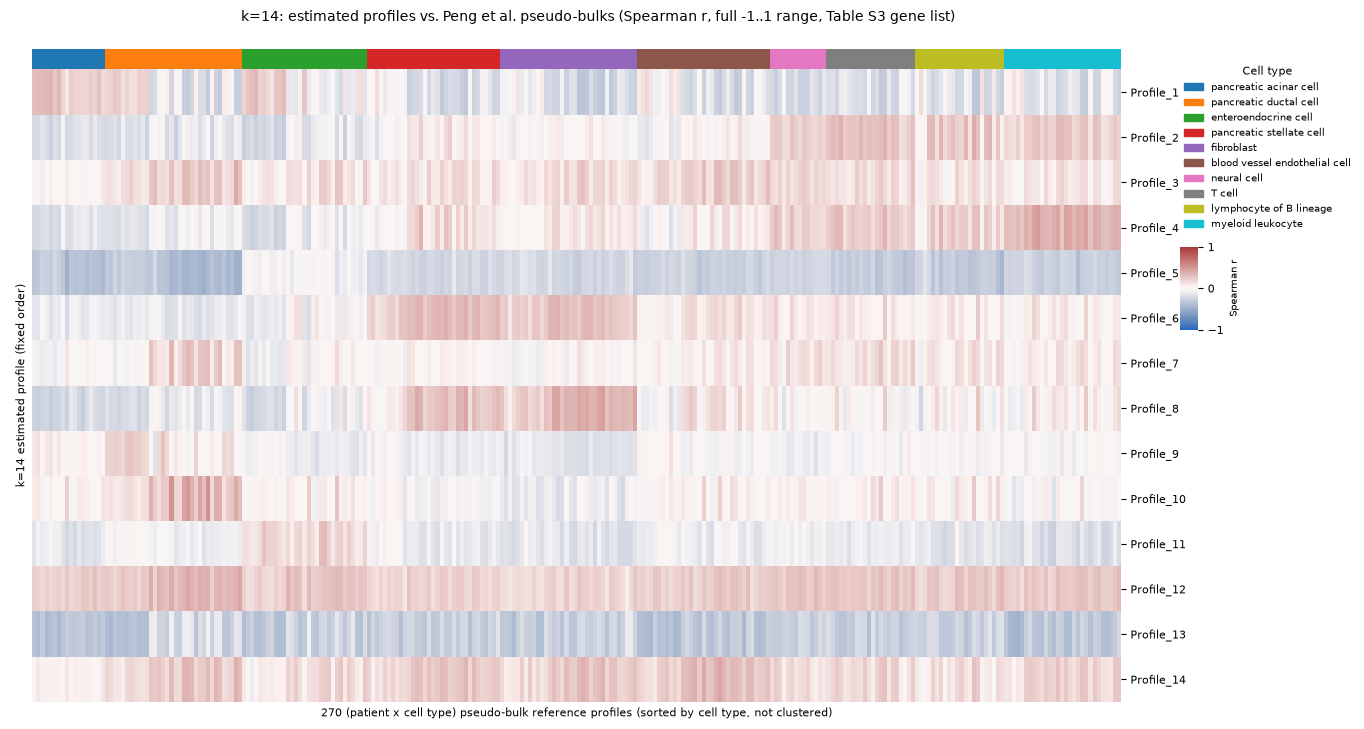

In [7]:
corr_k14_full = corr_by_k[k14]
print(f"k=14 full profile x pseudobulk matrix: min={corr_k14_full.values.min():.3f}, "
      f"max={corr_k14_full.values.max():.3f}, "
      f"{(corr_k14_full.values < 0).mean():.1%} of entries negative")

g3 = sns.clustermap(
    corr_k14_full, row_cluster=False, col_cluster=False,
    col_colors=pb_col_colors.values,
    cmap="vlag", vmin=-1, vmax=1, center=0,
    xticklabels=False, yticklabels=True,
    figsize=(12, 0.35 * k14 + 2), cbar_kws={"label": "Spearman r"},
    dendrogram_ratio=(0.02, 0.02),
)
g3.ax_heatmap.set_xlabel(f"{corr_k14_full.shape[1]} (patient x cell type) pseudo-bulk reference profiles (sorted by cell type, not clustered)")
g3.ax_heatmap.set_ylabel("k=14 estimated profile (fixed order)")
g3.ax_heatmap.yaxis.set_label_position("left")
g3.ax_heatmap.tick_params(axis="y", rotation=0)
handles = [plt.Rectangle((0, 0), 1, 1, color=cell_palette[t]) for t in cell_type_order]
legend3 = g3.ax_heatmap.legend(handles, cell_type_order, title="Cell type", bbox_to_anchor=(1.05, 1.02),
                                loc="upper left", fontsize=7, title_fontsize=8, frameon=False)
g3.fig.suptitle("k=14: estimated profiles vs. Peng et al. pseudo-bulks (Spearman r, full -1..1 range, Table S3 gene list)",
                 y=1.02, fontsize=10)

g3.cax.yaxis.label.set_fontsize(7)
g3.fig.canvas.draw()
legend_bbox = legend3.get_window_extent(g3.fig.canvas.get_renderer()).transformed(g3.fig.transFigure.inverted())
cbar_width, cbar_height, gap = 0.015, 0.12, 0.02
g3.cax.set_position([legend_bbox.x0, legend_bbox.y0 - cbar_height - gap, cbar_width, cbar_height])

g3.savefig(os.path.join(FIG_DIR, "fig_profile_reference_correlation_clustermap_k14_full_range.png"), dpi=200, bbox_inches="tight")
plt.show()
